# EDA 09: khung giờ home / office

**Câu hỏi:** khung "đêm" và "giờ làm việc" dùng để gán home/office (A10) nên chọn thế nào, và kết quả có nhạy với mốc giờ không?

Hiện chỉ có khung thử ở slide CP1: đêm 20–7h mọi ngày, giờ làm việc T2–T6 9–18h. Hai khung này chưa có căn cứ số liệu. EDA mục 12 (notebook 05) không đủ làm căn cứ, vì nó đếm **phút có điểm GPS**, tức lúc máy bật. Người dùng GeoLife thường tắt máy khi đứng yên (A12), nên giờ ít dữ liệu lại chính là giờ ở nhà. Notebook này đo **thời gian có mặt ở từng địa điểm**, tính trên stay.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 24 | Thời gian có mặt ở các địa điểm đầu phân bố theo giờ, thứ thế nào? Bao nhiêu phần là quan sát (GPS), bao nhiêu là suy ra (khoảng trống)? | Khung có đo dữ liệu thật hay không (A10, A12) |
| 25 | Người dùng đến và rời mỗi địa điểm lúc mấy giờ? Đêm nào họ ở đâu (mốc 3h sáng)? | Mốc bắt đầu, kết thúc của khung (A10) |
| 26 | Dời mốc khung đêm, khung làm việc thì bao nhiêu user đổi home / office? | Mốc cụ thể có quan trọng không (A10) |
| 26.1–26.5 | Giờ nào trong ngày thường user ở nơi làm việc nhiều hơn nơi ở? Đọc khung làm việc từ dữ liệu, kèm độ bất định | Khung làm việc ở bước 7 (A10, D2) |

**Đầu vào:** `data/processed/places_v1/<user>_stays` (stay kèm `place_id`, 0 là nơi nhiều giờ nhất) và `data/processed/clean` (để biết khoảng trống nằm ở đâu trong stay). Chỉ xét 5 địa điểm nhiều giờ nhất mỗi user (`TOP_K`).

**Trước khi chạy:** chạy lại `clean_trajectory.py --save-clean`, `stays/detect.py`, `places/cluster_v1.py` theo D12 (giờ địa phương mới). Kết quả lưu tạm ở `data/interim/eda_presence`; sau khi chạy lại pipeline phải đặt `REFRESH = True` một lần.

**Quy ước:**
- Mỗi stay tách thành phần **gps** (các bước ≤ 30 phút, A7) và phần **gap** (khoảng trống > 30 phút bên trong stay, A12).
- Giờ địa phương theo `tz_offset_h` của stay. Thứ trong tuần theo ngày địa phương của từng phút: 1h sáng thứ Bảy thuộc thứ Bảy.
- Cuối tuần là T7, CN. **Chưa tính ngày lễ, ngày làm bù** của Trung Quốc (để mục sau).
- Khi gộp nhiều user, mỗi user có trọng số bằng nhau (chuẩn hoá theo user trước khi lấy trung bình), để vài user nhiều dữ liệu không lấn át.
- Mục 26.1–26.5 đọc khung làm việc từ dữ liệu bằng một quy tắc nêu rõ. Mọi mốc trong notebook là mốc đọc phân phối (D2). Phép gán home/office ở mục 26 chỉ để đo độ nhạy, không phải quy tắc của bước 7.

Code tính toán: `src/eda/presence.py`, `src/eda/work_window.py` (mục 26.1–26.5).

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda import presence as pr
from eda.config import WEEKDAYS
from eda import split

USERS_LIMIT = None     # ví dụ ["001", "002", "003"] để chạy thử
REFRESH = False        # True sau khi chạy lại pipeline (stay, địa điểm)

pd.set_option("display.max_columns", 40)

users = list(USERS_LIMIT) if USERS_LIMIT else split.dev_users()   # chỉ nhóm dev (D17)
IV = pr.load_intervals(users, refresh=REFRESH)       # khoảng có mặt: user, place_id, kind, a_loc, b_loc
ST = pr.load_stays(users)                            # stay của top 5 địa điểm
PROF = pr.profiles(IV)                               # phút theo (user, place_id, kind) x 168 ô thứ*24 + giờ
print(f"{IV['user'].nunique()} user, {len(ST):,} stay, {len(IV):,} khoảng")

[20/122] tới user 031 (2 giây)
[40/122] tới user 058 (3 giây)
[60/122] tới user 091 (4 giây)
[80/122] tới user 117 (4 giây)
[100/122] tới user 147 (5 giây)
[120/122] tới user 177 (6 giây)
[122/122] tới user 179 (6 giây)
114 user, 6,517 stay, 17,664 khoảng


## 24. Thời gian có mặt theo giờ: quan sát hay suy ra

**Câu hỏi:** ở các địa điểm đầu, thời gian có mặt dồn vào giờ nào, thứ nào? Phần nào có điểm GPS, phần nào nằm trong khoảng trống?

Nếu gần hết thời gian ở mọi giờ đều là khoảng trống, thì đếm phút trong khung giờ chủ yếu là đếm thời gian **suy ra**: một gap-stay dài 20 giờ đóng góp vào cả khung đêm lẫn khung làm việc.

In [2]:
d = IV.assign(h=(IV["b_loc"] - IV["a_loc"]) / 3600)
tb = d.pivot_table(index="place_id", columns="kind", values="h", aggfunc="sum", fill_value=0)
tb["tổng_giờ"] = tb.sum(axis=1)
tb["% gap"] = tb["gap"] / tb["tổng_giờ"] * 100
tb["số_user"] = d.groupby("place_id")["user"].nunique()
display(tb.round(1))

dur = ST["duration_min"] / 60
print("Thời lượng stay (giờ), phân vị 50/75/90/99:", dur.quantile([.5, .75, .9, .99]).round(1).tolist())
for c in (6, 12, 20):
    print(f"  phần thời gian đến từ stay >= {c} giờ: {dur[dur >= c].sum() / dur.sum() * 100:.1f}%")

kind,gap,gps,tổng_giờ,% gap,số_user
place_id,,,,,
0,21101.6,1688.3,22789.8,92.6,114
1,11928.3,735.0,12663.3,94.2,110
2,5469.7,406.0,5875.7,93.1,102
3,2299.5,221.7,2521.2,91.2,92
4,1516.0,157.3,1673.3,90.6,86


Thời lượng stay (giờ), phân vị 50/75/90/99: [5.6, 11.6, 14.4, 22.0]
  phần thời gian đến từ stay >= 6 giờ: 85.6%
  phần thời gian đến từ stay >= 12 giờ: 49.3%
  phần thời gian đến từ stay >= 20 giờ: 7.7%


**Hồ sơ theo thứ × giờ** của địa điểm 0, 1, 2. Mỗi ô là tỷ lệ thời gian của user ở địa điểm đó rơi vào ô ấy, trung bình qua các user (mỗi user trọng số bằng nhau). Hàng trên: phần GPS; hàng dưới: phần khoảng trống. Hai hàng chung một thang màu cho mỗi địa điểm.

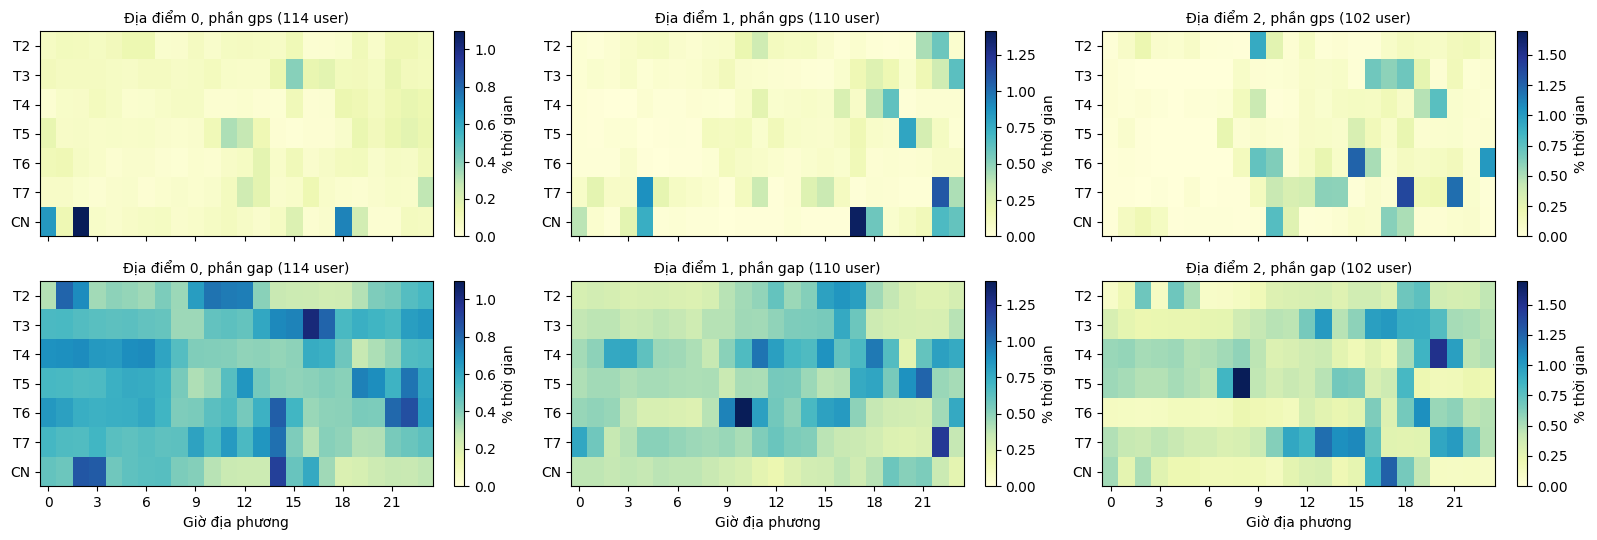

In [3]:
def user_norm(place, kind):
    """Trung bình qua user của tỷ lệ phút theo ô (7 x 24); mẫu số = tổng phút (gps + gap) của user ở địa điểm đó."""
    tot = PROF.xs(place, level="place_id").groupby(level="user").sum().sum(axis=1)
    users_at = tot.index
    try:
        x = PROF.xs((place, kind), level=("place_id", "kind"))
    except KeyError:
        return np.zeros((7, 24)), len(users_at)
    x = x.reindex(users_at, fill_value=0).div(tot, axis=0)
    return x.mean(axis=0).to_numpy().reshape(7, 24) * 100, len(users_at)

fig, axes = plt.subplots(2, 3, figsize=(16, 5.5), sharex=True)
for j, place in enumerate((0, 1, 2)):
    mats = {k: user_norm(place, k) for k in ("gps", "gap")}
    vmax = max(m.max() for m, _ in mats.values())
    for i, kind in enumerate(("gps", "gap")):
        m, n = mats[kind]
        ax = axes[i, j]
        im = ax.imshow(m, aspect="auto", cmap="YlGnBu", vmin=0, vmax=vmax)
        ax.set_yticks(range(7)); ax.set_yticklabels(WEEKDAYS)
        ax.set_xticks(range(0, 24, 3))
        ax.set_title(f"Địa điểm {place}, phần {kind} ({n} user)", fontsize=10)
        fig.colorbar(im, ax=ax, fraction=0.03, label="% thời gian")
for ax in axes[-1]:
    ax.set_xlabel("Giờ địa phương")
plt.tight_layout(); plt.show()

**Tỷ lệ khoảng trống theo giờ:** trong mỗi giờ của ngày, bao nhiêu phần thời gian có mặt là khoảng trống (gộp mọi thứ, mọi user).

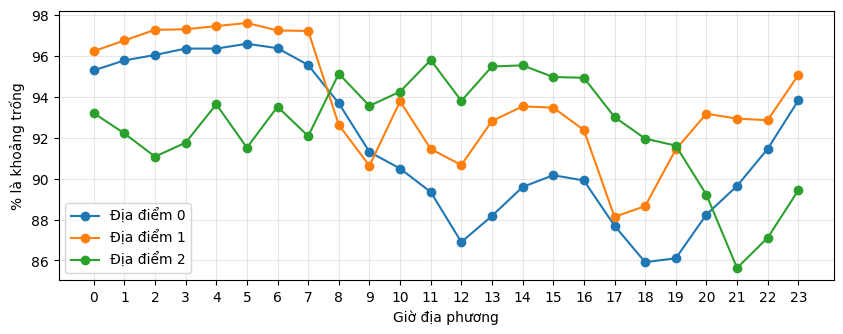

giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
địa điểm 0,95.0,96.0,96.0,96.0,96.0,97.0,96.0,96.0,94.0,91.0,90.0,89.0,87.0,88.0,90.0,90.0,90.0,88.0,86.0,86.0,88.0,90.0,91.0,94.0
địa điểm 1,96.0,97.0,97.0,97.0,97.0,98.0,97.0,97.0,93.0,91.0,94.0,91.0,91.0,93.0,94.0,93.0,92.0,88.0,89.0,91.0,93.0,93.0,93.0,95.0
địa điểm 2,93.0,92.0,91.0,92.0,94.0,92.0,94.0,92.0,95.0,94.0,94.0,96.0,94.0,95.0,96.0,95.0,95.0,93.0,92.0,92.0,89.0,86.0,87.0,89.0


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
rows = {}
for place in (0, 1, 2):
    p = PROF.xs(place, level="place_id").groupby(level="kind").sum()
    by = p.to_numpy().reshape(-1, 7, 24).sum(axis=1)          # [kind, giờ]
    kinds = list(p.index)
    gap = by[kinds.index("gap")] if "gap" in kinds else np.zeros(24)
    share = gap / np.maximum(by.sum(axis=0), 1e-9) * 100
    rows[f"địa điểm {place}"] = share
    ax.plot(range(24), share, marker="o", label=f"Địa điểm {place}")
ax.set_xticks(range(24)); ax.set_xlabel("Giờ địa phương"); ax.set_ylabel("% là khoảng trống")
ax.legend(); ax.grid(alpha=.3); plt.show()
display(pd.DataFrame(rows, index=pd.Index(range(24), name="giờ")).T.round(0))

**Cần đọc ra ở mục 24 (điền sau khi chạy):**
- Phần GPS có hình dạng ngày/đêm rõ hơn phần khoảng trống không? Ở giờ nào hai hàng khác nhau nhiều nhất?
- Nếu tỷ lệ khoảng trống cao đều ở mọi giờ, phép đếm phút trong khung không nên coi phần khoảng trống ngang với phần GPS (bước 7 có thể giảm trọng số `gap_min`, như A12 đã ghi).
- Địa điểm 0 và 1 có hồ sơ khác nhau rõ (một nơi đêm, một nơi ngày thường) hay giống nhau?

## 25. Giờ đến, giờ đi và đêm có mặt

**Câu hỏi:** người dùng đến và rời mỗi địa điểm lúc mấy giờ, ngày thường và cuối tuần khác nhau thế nào?

Giờ đến là điểm GPS đầu tiên của stay, giờ đi là điểm GPS cuối cùng: cả hai đều quan sát được, kể cả với gap-stay. Vì vậy đây là tín hiệu thật hơn phút có mặt. Nơi ở thường đến buổi tối, rời buổi sáng; nơi làm việc ngược lại. Chỗ phân phối đổi chiều gợi ý mốc khung.

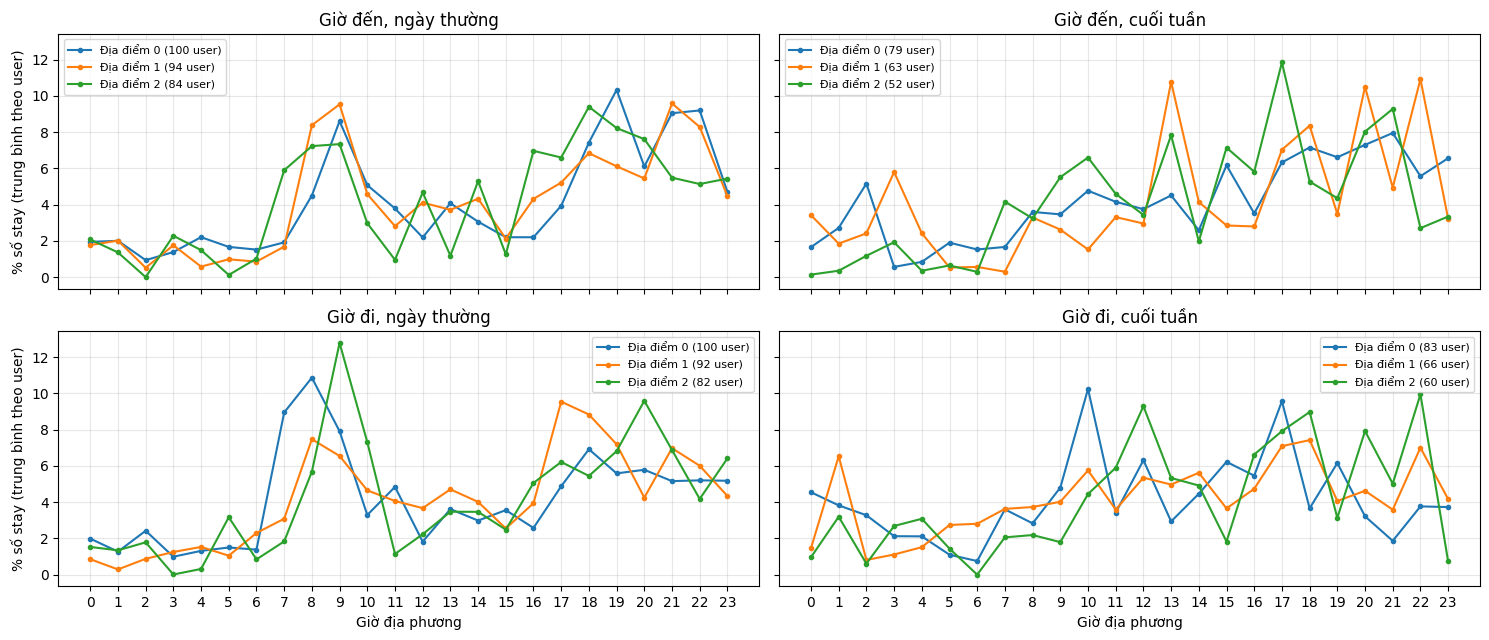

In [5]:
AL = pr.arrive_leave(ST)

def user_hist(df, col, wk_col, wk):
    """Phân phối giờ (24) trung bình qua user, mỗi user trọng số bằng nhau."""
    x = df[df[wk_col] == wk]
    if not len(x):
        return np.zeros(24), 0
    h = x.groupby("user")[col].apply(lambda s: np.bincount(s, minlength=24) / len(s))
    return np.vstack(h.to_numpy()).mean(axis=0) * 100, len(h)

fig, axes = plt.subplots(2, 2, figsize=(15, 6.5), sharex=True, sharey=True)
for i, (col, wk_col, name) in enumerate([("arrive_h", "arrive_wkend", "Giờ đến"), ("leave_h", "leave_wkend", "Giờ đi")]):
    for j, wk in enumerate((False, True)):
        ax = axes[i, j]
        for place in (0, 1, 2):
            v, n = user_hist(AL[AL["place_id"] == place], col, wk_col, wk)
            ax.plot(range(24), v, marker="o", ms=3, label=f"Địa điểm {place} ({n} user)")
        ax.set_title(f"{name}, {'cuối tuần' if wk else 'ngày thường'}")
        ax.set_xticks(range(24)); ax.grid(alpha=.3); ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Giờ địa phương")
for ax in axes[:, 0]:
    ax.set_ylabel("% số stay (trung bình theo user)")
plt.tight_layout(); plt.show()

In [6]:
# Bảng số của hình trên (ngày thường): giờ đến, giờ đi theo địa điểm
tb = {}
for col, wk_col, name in [("arrive_h", "arrive_wkend", "đến"), ("leave_h", "leave_wkend", "đi")]:
    for place in (0, 1, 2):
        tb[f"{name} · đđ {place}"] = user_hist(AL[AL["place_id"] == place], col, wk_col, False)[0]
display(pd.DataFrame(tb, index=pd.Index(range(24), name="giờ")).T.round(1))

giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
đến · đđ 0,1.9,2.0,0.9,1.4,2.2,1.7,1.5,1.9,4.5,8.6,5.1,3.8,2.2,4.1,3.1,2.2,2.2,3.9,7.4,10.3,6.1,9.0,9.2,4.7
đến · đđ 1,1.8,2.0,0.5,1.8,0.6,1.0,0.9,1.7,8.4,9.5,4.6,2.8,4.1,3.7,4.3,2.1,4.3,5.2,6.8,6.1,5.4,9.6,8.3,4.5
đến · đđ 2,2.1,1.4,0.0,2.3,1.5,0.1,1.0,5.9,7.2,7.3,3.0,1.0,4.7,1.2,5.3,1.3,7.0,6.6,9.4,8.2,7.6,5.5,5.1,5.4
đi · đđ 0,2.0,1.3,2.4,1.0,1.3,1.5,1.4,8.9,10.9,7.9,3.3,4.8,1.8,3.6,3.0,3.6,2.6,4.9,6.9,5.6,5.8,5.2,5.2,5.2
đi · đđ 1,0.9,0.3,0.9,1.2,1.5,1.0,2.3,3.1,7.5,6.5,4.7,4.1,3.7,4.7,4.0,2.6,3.9,9.5,8.8,7.2,4.3,7.0,6.0,4.3
đi · đđ 2,1.5,1.3,1.8,0.0,0.3,3.2,0.8,1.8,5.7,12.8,7.3,1.1,2.2,3.5,3.5,2.5,5.1,6.2,5.4,6.8,9.6,6.9,4.2,6.4


**Đêm có mặt:** với mỗi địa điểm, đếm số đêm khác nhau mà user có mặt lúc 3h sáng (giờ ít dữ liệu nhất, EDA mục 12, nên hầu như chỉ ai ở yên một chỗ mới có mặt lúc đó). "Nơi qua đêm" của user là địa điểm có nhiều đêm nhất. So với địa điểm 0 (nhiều giờ nhất): nếu thường trùng thì xếp theo tổng giờ đã gần đủ; nếu không, nơi ở phải được chọn theo đêm chứ không theo tổng giờ.

In [7]:
nights = {}
for name, kinds in [("gps + gap", ("gps", "gap")), ("chỉ gps", ("gps",))]:
    n = pr.nights_present(IV, kinds=kinds)
    top = n.sort_values(["user", "n_nights"], ascending=[True, False]).groupby("user").head(1)
    tot = n.groupby("user")["n_nights"].sum()
    top = top.assign(share=top["n_nights"].to_numpy() / tot.reindex(top["user"]).to_numpy())
    nights[name] = top.set_index("user")
    print(f"[{name}] {len(top)} user có ít nhất 1 đêm ở top 5 địa điểm")
    print("  nơi qua đêm là địa điểm:", top["place_id"].value_counts().sort_index().to_dict())
    print("  số đêm ở nơi qua đêm, phân vị 25/50/75:", top["n_nights"].quantile([.25, .5, .75]).tolist())
    print("  tỷ lệ đêm ở nơi qua đêm (trong top 5), trung vị:", round(float(top["share"].median()), 2))
n_all = IV["user"].nunique()
print(f"User không có đêm nào (gps + gap): {n_all - len(nights['gps + gap'])} / {n_all}")

[gps + gap] 90 user có ít nhất 1 đêm ở top 5 địa điểm
  nơi qua đêm là địa điểm: {0: 68, 1: 19, 2: 1, 3: 2}
  số đêm ở nơi qua đêm, phân vị 25/50/75: [2.0, 5.0, 10.0]
  tỷ lệ đêm ở nơi qua đêm (trong top 5), trung vị: 0.74
[chỉ gps] 33 user có ít nhất 1 đêm ở top 5 địa điểm
  nơi qua đêm là địa điểm: {0: 18, 1: 6, 2: 3, 3: 3, 4: 3}
  số đêm ở nơi qua đêm, phân vị 25/50/75: [1.0, 2.0, 3.0]
  tỷ lệ đêm ở nơi qua đêm (trong top 5), trung vị: 1.0
User không có đêm nào (gps + gap): 24 / 114


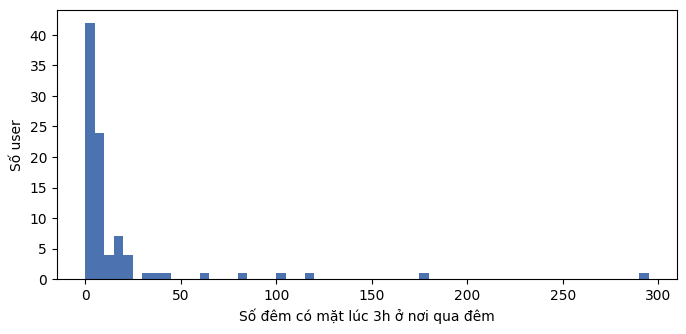

,< 3 đêm,< 7 đêm,< 14 đêm,< 30 đêm
số user,27,52,69,81


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
v = nights["gps + gap"]["n_nights"]
ax.hist(v, bins=np.arange(0, v.max() + 6, 5), color="#4c72b0")
ax.set_xlabel("Số đêm có mặt lúc 3h ở nơi qua đêm"); ax.set_ylabel("Số user")
plt.show()
display(pd.DataFrame({f"< {k} đêm": [int((v < k).sum())] for k in (3, 7, 14, 30)}, index=["số user"]))

**Cần đọc ra ở mục 25 (điền sau khi chạy):**
- Giờ đến nơi qua đêm tập trung từ mấy giờ, giờ rời đi tập trung tới mấy giờ? Đó là căn cứ cho mốc đầu, mốc cuối của khung đêm.
- Ngày thường, giờ đến và giờ đi ở nơi còn lại (ứng viên office) nằm ở đâu? Đó là căn cứ cho khung làm việc.
- Cuối tuần lệch bao nhiêu giờ so với ngày thường?
- Bao nhiêu user có nơi qua đêm khác địa điểm 0? Bao nhiêu user có quá ít đêm (gợi ý cho A11)?

## 26. Độ nhạy của kết quả theo mốc khung

**Câu hỏi:** nếu dời mốc khung đêm hoặc khung làm việc, bao nhiêu user đổi home hoặc office?

Phép gán thử (chỉ để đo, không phải quy tắc bước 7): home = địa điểm có nhiều phút trong khung đêm nhất; office = địa điểm có nhiều phút trong khung làm việc T2–T6 nhất, khác home. `home=office` đếm số user mà chính home cũng là nơi nhiều phút làm việc nhất (ở và làm cùng chỗ, hoặc khung không tách được). Mốc so sánh là khung ở slide CP1 (`BASE_WINDOWS`: đêm 20–7h, làm việc 9–18h). Mỗi lần chỉ đổi một khung, giữ khung kia.

Nếu số user đổi kết quả nhỏ trên cả vùng lưới, mốc cụ thể không quan trọng và có thể chọn theo mục 25. Nếu lớn, những user đó cần vào mẫu đánh giá thủ công (A13).

In [9]:
print("Khung gốc:", pr.BASE_WINDOWS, "| số user:", IV["user"].nunique())
for name, kinds in [("gps + gap", ("gps", "gap")), ("chỉ gps", ("gps",))]:
    print(f"\n[{name}]")
    display(pr.sensitivity(PROF, kinds=kinds))

Khung gốc: {'night': (20, 7), 'work': (9, 18)} | số user: 114

[gps + gap]


,đổi,khung,home_khác,office_khác,home=office
0,đêm,19–5h,13,7,29
1,đêm,19–6h,8,4,26
2,đêm,19–7h,5,1,27
3,đêm,19–8h,7,2,28
4,đêm,20–5h,5,4,26
5,đêm,20–6h,3,3,25
6,đêm,20–7h,0,0,26
7,đêm,20–8h,4,2,26
8,đêm,21–5h,5,2,24
9,đêm,21–6h,5,3,23



[chỉ gps]


,đổi,khung,home_khác,office_khác,home=office
0,đêm,19–5h,16,7,28
1,đêm,19–6h,15,7,28
2,đêm,19–7h,14,6,29
3,đêm,19–8h,15,6,29
4,đêm,20–5h,4,1,24
5,đêm,20–6h,3,1,24
6,đêm,20–7h,0,0,25
7,đêm,20–8h,6,3,28
8,đêm,21–5h,19,6,25
9,đêm,21–6h,18,6,25


**Phần khoảng trống có làm đổi kết quả không:** so phép gán ở khung gốc khi tính cả khoảng trống và khi chỉ tính phần GPS.

In [10]:
b = pr.BASE_WINDOWS
a1 = pr.assign(PROF, b["night"], b["work"], ("gps", "gap")).set_index("user")
a2 = pr.assign(PROF, b["night"], b["work"], ("gps",)).set_index("user").reindex(a1.index)
cmp = pd.DataFrame({
    "home khác nhau": [int((a1["home"] != a2["home"]).sum())],
    "office khác nhau": [int((a1["office"] != a2["office"]).sum())],
    "home là địa điểm 0 (gps + gap)": [int((a1["home"] == 0).sum())],
    "không có home (gps + gap)": [int((a1["home"] < 0).sum())],
    "không có office (gps + gap)": [int((a1["office"] < 0).sum())],
    "home=office (gps + gap)": [int(a1["same"].sum())],
}, index=["số user"])
display(cmp)

,home khác nhau,office khác nhau,home là địa điểm 0 (gps + gap),không có home (gps + gap),không có office (gps + gap),home=office (gps + gap)
số user,37,51,80,6,16,26


**Cần đọc ra ở mục 26 (điền sau khi chạy):**
- Trong lưới, mốc nào làm nhiều user đổi kết quả nhất? Kết quả có ổn định quanh khung gốc không?
- Tính hay không tính phần khoảng trống làm bao nhiêu user đổi home/office?
- Bao nhiêu user có `home=office`? Đây là nhóm cần quy tắc riêng ở bước 7 (cho phép home trùng office, hoặc trả "không xác định office").

**Chưa làm trong notebook này** (xem tài liệu review A10): ngày lễ và ngày làm bù của Trung Quốc 2007–2012, phân loại nhịp sinh hoạt theo user (ca đêm), khoảng cách home–office, độ ổn định theo tháng và lấy mẫu số ngày cho A11.

## 26.1–26.5. Đọc khung giờ làm việc từ dữ liệu

**Câu hỏi:** giờ nào trong ngày thường thì một user ở nơi làm việc nhiều hơn ở nơi ở? Đó là khung làm việc dùng để tách office khỏi home.

Không dùng giờ hành chính làm đầu vào. Cách làm:
1. Với mỗi user chọn **nơi ở** (nhiều phút nhất lúc 0–5h mọi ngày) và **nơi làm việc ứng viên** (nơi khác nhiều phút nhất lúc 10–16h T2–T6). Hai khung chọn này hẹp, nằm giữa đêm và giữa ngày, nên không quyết định biên của khung cần tìm.
2. Mỗi (thứ, giờ) tính `office / (office + home)` theo phút có mặt, trung bình qua các user (trọng số bằng nhau).
3. Khung làm việc là đoạn giờ liên tiếp dài nhất của ngày thường mà tỷ lệ này ≥ 0,5. Cuối tuần cùng đường cong là đối chứng: nếu nơi ứng viên thật là nơi làm việc thì cuối tuần phải thấp.
4. Độ bất định: lấy mẫu lại user 300 lần, tính lại biên.

**Giới hạn:** user không có đủ cặp (không có đêm hoặc không có nơi khác) bị loại, nên khung chỉ nói về nhóm user có cả hai nơi. Phần `gap` gán cả đoạn máy tắt cho một nơi nên làm biên mờ; vì vậy mọi bảng chạy cả hai cách (`gps`, `gps + gap`). Chưa trừ ngày lễ và ngày làm bù (để mục sau).

In [11]:
from eda import work_window as ww

KINDS = {"gps + gap": ("gps", "gap"), "chỉ gps": ("gps",)}
PAIRS, SHARE = {}, {}
for name, kinds in KINDS.items():
    PAIRS[name] = ww.pick_pairs(PROF, kinds=kinds)
    SHARE[name] = ww.office_share(PROF, PAIRS[name], kinds=kinds)
    p = PAIRS[name]
    print(f"[{name}] {len(p)} user | có home: {(p['home'] >= 0).sum()} | có office ứng viên: {(p['office'] >= 0).sum()} "
          f"| đủ cặp: {len(SHARE[name])} | office ứng viên là địa điểm: {p.loc[p['office'] >= 0, 'office'].value_counts().sort_index().to_dict()}")

[gps + gap] 114 user | có home: 85 | có office ứng viên: 79 | đủ cặp: 71 | office ứng viên là địa điểm: {0: 25, 1: 40, 2: 8, 3: 4, 4: 2}
[chỉ gps] 114 user | có home: 32 | có office ứng viên: 22 | đủ cặp: 11 | office ứng viên là địa điểm: {0: 5, 1: 11, 2: 3, 3: 3}


### 26.2. Tỷ lệ ở nơi làm việc theo giờ: ngày thường so với cuối tuần

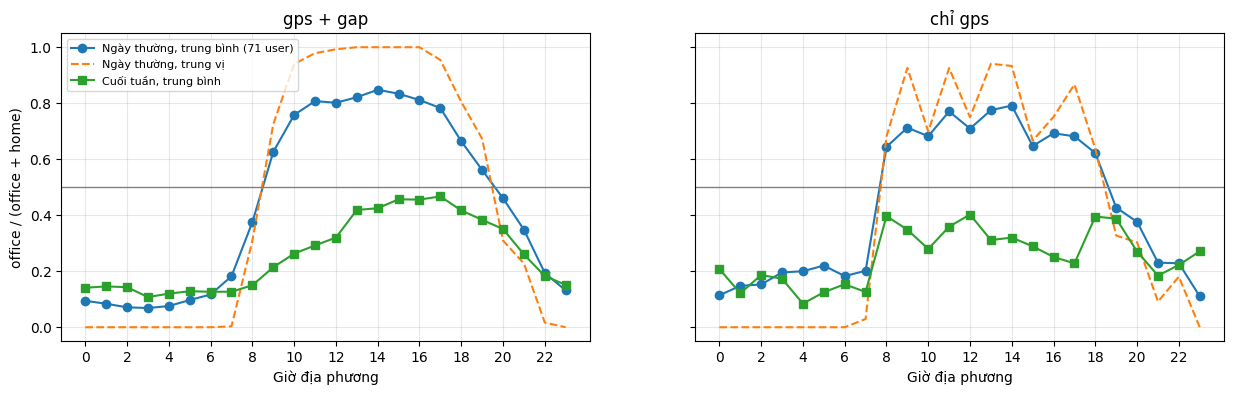

giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
gps + gap · ngày thường,0.09,0.08,0.07,0.07,0.08,0.10,0.12,0.18,0.38,0.63,0.76,0.81,0.80,0.82,0.85,0.83,0.81,0.78,0.66,0.56,0.46,0.35,0.19,0.13
gps + gap · cuối tuần,0.14,0.15,0.14,0.11,0.12,0.13,0.13,0.13,0.15,0.21,0.26,0.29,0.32,0.42,0.43,0.46,0.46,0.47,0.42,0.38,0.35,0.26,0.18,0.15
gps + gap · số user ngày thường,68.00,68.00,68.00,69.00,69.00,69.00,69.00,69.00,70.00,69.00,70.00,70.00,71.00,71.00,70.00,69.00,70.00,69.00,69.00,68.00,66.00,67.00,68.00,68.00
chỉ gps · ngày thường,0.11,0.15,0.15,0.20,0.20,0.22,0.18,0.20,0.64,0.71,0.68,0.77,0.71,0.78,0.79,0.65,0.69,0.68,0.62,0.43,0.38,0.23,0.23,0.11
chỉ gps · cuối tuần,0.21,0.12,0.19,0.17,0.08,0.12,0.15,0.13,0.40,0.35,0.28,0.36,0.40,0.31,0.32,0.29,0.25,0.23,0.40,0.39,0.27,0.18,0.22,0.27
chỉ gps · số user ngày thường,10.00,9.00,10.00,10.00,11.00,10.00,10.00,11.00,11.00,11.00,10.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00,11.00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
CURVES = {}
for ax, (name, sh) in zip(axes, SHARE.items()):
    wd, wd_med, n_wd = ww.hourly_share(sh, slice(0, 5))
    we, _, n_we = ww.hourly_share(sh, slice(5, 7))
    CURVES[name] = (wd, wd_med, we, n_wd, n_we)
    ax.plot(range(24), wd, marker="o", label=f"Ngày thường, trung bình ({len(sh)} user)")
    ax.plot(range(24), wd_med, ls="--", label="Ngày thường, trung vị")
    ax.plot(range(24), we, marker="s", label="Cuối tuần, trung bình")
    ax.axhline(ww.WIN_SHARE, color="grey", lw=1)
    ax.set_title(name); ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Giờ địa phương"); ax.grid(alpha=.3)
axes[0].set_ylabel("office / (office + home)"); axes[0].legend(fontsize=8)
plt.show()
tb = {}
for name, (wd, wd_med, we, n_wd, n_we) in CURVES.items():
    tb[f"{name} · ngày thường"] = wd; tb[f"{name} · cuối tuần"] = we; tb[f"{name} · số user ngày thường"] = n_wd
display(pd.DataFrame(tb, index=pd.Index(range(24), name="giờ")).T.round(2))

### 26.3. Khung theo quy tắc, các biến thể và độ bất định

In [13]:
rows = []
for name, sh in SHARE.items():
    wd, wd_med, we, _, _ = CURVES[name]
    for thr in (0.33, 0.5, 0.67):
        w = ww.window_from_curve(wd, thr)
        rows.append({"nguồn": name, "đường": "trung bình", "ngưỡng": thr, "khung": f"{w[0]}–{w[1]}h" if w else "không có"})
    w = ww.window_from_curve(wd_med, ww.WIN_SHARE)
    rows.append({"nguồn": name, "đường": "trung vị", "ngưỡng": ww.WIN_SHARE, "khung": f"{w[0]}–{w[1]}h" if w else "không có"})
    w = ww.window_from_curve(we, ww.WIN_SHARE)
    rows.append({"nguồn": name, "đường": "cuối tuần (đối chứng)", "ngưỡng": ww.WIN_SHARE, "khung": f"{w[0]}–{w[1]}h" if w else "không có"})
display(pd.DataFrame(rows))

# chọn nơi làm việc ứng viên bằng giờ lõi khác (9–17h) có đổi khung không
rows = []
for name, kinds in KINDS.items():
    p2 = ww.pick_pairs(PROF, kinds=kinds, core=ww.CORE_ALT)
    sh2 = ww.office_share(PROF, p2, kinds=kinds)
    w = ww.window_from_curve(ww.hourly_share(sh2, slice(0, 5))[0])
    base = PAIRS[name]
    rows.append({"nguồn": name, f"lõi {ww.CORE_HOURS[0]}–{ww.CORE_HOURS[1]}h": f"{ww.window_from_curve(CURVES[name][0])}",
                 f"lõi {ww.CORE_ALT[0]}–{ww.CORE_ALT[1]}h": f"{w}",
                 "số user đổi nơi ứng viên": int((p2["office"] != base["office"].reindex(p2.index)).sum())})
display(pd.DataFrame(rows))

bs = {}
for name, sh in SHARE.items():
    b = ww.bootstrap_window(sh)
    bs[name] = b
    print(f"[{name}] lấy mẫu lại {len(b)} lần: không có khung ở {int(b['start'].isna().sum())} lần")
    print("   giờ bắt đầu, phân vị 2,5/50/97,5:", b["start"].quantile([.025, .5, .975]).tolist())
    print("   giờ kết thúc, phân vị 2,5/50/97,5:", b["end"].quantile([.025, .5, .975]).tolist())

,nguồn,đường,ngưỡng,khung
0,gps + gap,trung bình,0.33,8–22h
1,gps + gap,trung bình,0.50,9–20h
2,gps + gap,trung bình,0.67,10–18h
3,gps + gap,trung vị,0.50,9–20h
4,gps + gap,cuối tuần (đối chứng),0.50,không có
5,chỉ gps,trung bình,0.33,8–21h
6,chỉ gps,trung bình,0.50,8–19h
7,chỉ gps,trung bình,0.67,9–15h
8,chỉ gps,trung vị,0.50,8–19h
9,chỉ gps,cuối tuần (đối chứng),0.50,không có


,nguồn,lõi 10–16h,lõi 9–17h,số user đổi nơi ứng viên
0,gps + gap,"(9, 20)","(9, 20)",4
1,chỉ gps,"(8, 19)","(8, 19)",5


[gps + gap] lấy mẫu lại 300 lần: không có khung ở 0 lần
   giờ bắt đầu, phân vị 2,5/50/97,5: [9.0, 9.0, 9.0]
   giờ kết thúc, phân vị 2,5/50/97,5: [19.0, 20.0, 21.0]
[chỉ gps] lấy mẫu lại 300 lần: không có khung ở 0 lần
   giờ bắt đầu, phân vị 2,5/50/97,5: [8.0, 8.0, 10.0]
   giờ kết thúc, phân vị 2,5/50/97,5: [15.0, 19.0, 21.0]


### 26.4. Giờ đến, giờ đi thật ở nơi làm việc ứng viên

Giờ đến là điểm GPS đầu tiên của stay, giờ đi là điểm GPS cuối. Chỉ lấy đến lúc 5–13h và đi lúc 12–23h, ngày thường, để bỏ các stay xuyên đêm. Máy bật muộn thì giờ đến lệch muộn, máy tắt sớm thì giờ đi lệch sớm, nên đây là cận trong của khung chứ không phải khung.

In [14]:
arr, lea = ww.arrive_leave_office(AL, PAIRS["gps + gap"])
def per_user_q(df, col):
    g = df.groupby("user")[col].median()
    return g
a_u, l_u = per_user_q(arr, "arrive_h"), per_user_q(lea, "leave_h")
q = [.1, .25, .5, .75, .9]
display(pd.DataFrame({
    "giờ đến, trung vị theo user": a_u.quantile(q).round(1).to_numpy(), "giờ đi, trung vị theo user": l_u.quantile(q).round(1).to_numpy(),
}, index=[f"phân vị {int(x * 100)}" for x in q]).T)
print(f"số user: đến {len(a_u)}, đi {len(l_u)} | số stay: đến {len(arr)}, đi {len(lea)}")

,phân vị 10,phân vị 25,phân vị 50,phân vị 75,phân vị 90
"giờ đến, trung vị theo user",7.0,8.0,9.0,10.0,11.4
"giờ đi, trung vị theo user",14.5,16.0,17.5,20.0,21.5


số user: đến 73, đi 79 | số stay: đến 1292, đi 1511


### 26.5. Khung dữ liệu so với khung gốc 9–18h

Với khung làm việc lấy từ 26.3 (trung bình, ngưỡng 0,5, cả hai nguồn), có bao nhiêu user đổi office so với khung gốc?

In [15]:
b = pr.BASE_WINDOWS
rows = []
for name, kinds in KINDS.items():
    w = ww.window_from_curve(CURVES[name][0])
    if not w:
        rows.append({"nguồn": name, "khung dữ liệu": "không có"}); continue
    ref = pr.assign(PROF, b["night"], b["work"], kinds).set_index("user")
    new = pr.assign(PROF, b["night"], w, kinds).set_index("user")
    rows.append({"nguồn": name, "khung dữ liệu": f"{w[0]}–{w[1]}h", "khung gốc": f"{b['work'][0]}–{b['work'][1]}h",
                 "office khác": int((new["office"] != ref["office"]).sum()),
                 "home=office (gốc)": int(ref["same"].sum()), "home=office (dữ liệu)": int(new["same"].sum())})
display(pd.DataFrame(rows))

,nguồn,khung dữ liệu,khung gốc,office khác,home=office (gốc),home=office (dữ liệu)
0,gps + gap,9–20h,9–18h,10,26,29
1,chỉ gps,8–19h,9–18h,16,25,35


**Cần đọc ra ở mục 26.1–26.5 (điền sau khi chạy):**
- Đường ngày thường vượt 0,5 từ giờ nào đến giờ nào? Cuối tuần có thấp hơn rõ không (nếu không, nơi ứng viên chưa phải nơi làm việc)?
- Hai nguồn (`gps`, `gps + gap`) và ba ngưỡng 0,33 / 0,5 / 0,67 cho khung gần nhau không? Biên nào dao động nhiều nhất?
- Khoảng lấy mẫu lại rộng bao nhiêu giờ? Nếu rộng hơn 1–2 giờ thì chỉ nên chốt khung theo cả hai biên với biên độ đó.
- Giờ đến, giờ đi thật (26.4) nằm trong hay ngoài khung của 26.3?
- Khung dữ liệu làm đổi bao nhiêu user so với 9–18h (26.5)? Nếu ít, giữ 9–18h cũng được; nếu nhiều, dùng khung dữ liệu.